# Assignment2

In [10]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

torch.manual_seed(42)  # reproduzierbare Ergebnisse
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(device)

cpu


## 1. Custom Dataset

In [11]:
class TitanicDataSet(Dataset):
    """Titanic-Datensatz mit Vorverarbeitung und 80/20 Train/Val-Split."""

    NUMERIC = ["Pclass", "Age", "SibSp", "Parch", "Fare"]  # werden standardisiert
    CATEGORICAL = ["Sex", "Embarked"]  # werden one-hot-kodiert

    def __init__(self, csv_file, train=True, val_split=0.2, seed=42):
        df = pd.read_csv(csv_file)
        df = df[self.NUMERIC + self.CATEGORICAL + ["Survived"]].copy()

        # fester Seed -> train=True und train=False erhalten disjunkte Teile derselben Permutation
        perm = np.random.default_rng(seed).permutation(len(df))
        n_val = int(len(df) * val_split)
        train_idx, val_idx = perm[n_val:], perm[:n_val]
        train_df = df.iloc[train_idx]

        # fehlende Werte auffüllen (Statistiken nur aus den Trainingsdaten -> kein Data Leakage)
        df["Age"] = df["Age"].fillna(train_df["Age"].median())
        df["Embarked"] = df["Embarked"].fillna(train_df["Embarked"].mode()[0])

        # Skalierung: Standardisierung mit Mittelwert/Std der Trainingsdaten
        mean = df.iloc[train_idx][self.NUMERIC].mean()
        std = df.iloc[train_idx][self.NUMERIC].std()
        df[self.NUMERIC] = (df[self.NUMERIC] - mean) / std

        # One-Hot-Encoding für Sex (male/female) und Embarked (C/Q/S)
        df = pd.get_dummies(df, columns=self.CATEGORICAL, dtype=float)

        df = df.iloc[train_idx if train else val_idx]
        self.feature_names = [c for c in df.columns if c != "Survived"]
        self.X = torch.tensor(df[self.feature_names].values, dtype=torch.float32)
        self.y = torch.tensor(df["Survived"].values, dtype=torch.float32).unsqueeze(1)  # Form (N, 1) für BCE

    def __len__(self):
        return len(self.y)

    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]

In [12]:
titanic_train = TitanicDataSet('titanic.csv', train=True)
titanic_val = TitanicDataSet('titanic.csv', train=False)

print(len(titanic_train), len(titanic_val))
print(titanic_train.feature_names)
print(titanic_train[0])

713 178
['Pclass', 'Age', 'SibSp', 'Parch', 'Fare', 'Sex_female', 'Sex_male', 'Embarked_C', 'Embarked_Q', 'Embarked_S']
(tensor([ 0.8254, -0.1614, -0.4823, -0.4682, -0.4902,  0.0000,  1.0000,  0.0000,
         0.0000,  1.0000]), tensor([1.]))


## 2. Netz mit einer Hidden Layer (Größe 3), BCE-Loss, Batchgröße 16

In [13]:
train_loader = DataLoader(titanic_train, batch_size=16, shuffle=True)
val_loader = DataLoader(titanic_val, batch_size=16, shuffle=False)

D_in = len(titanic_train.feature_names)  # 10 Eingabefeatures


class SimpleNet(nn.Module):
    """Eine Hidden Layer mit 3 Neuronen, Sigmoid am Ausgang."""

    def __init__(self, D_in, H=3):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(D_in, H),
            nn.ReLU(),
            nn.Linear(H, 1),
            nn.Sigmoid(),  # Ausgabe = Überlebenswahrscheinlichkeit
        )

    def forward(self, x):
        return self.net(x)


criterion = nn.BCELoss()  # Binary Cross-Entropy


def train_epoch(model, optimizer):  # trainiert eine Epoche
    model.train()  # Trainingsmodus (relevant für Dropout)
    for data, target in train_loader:
        data, target = data.to(device), target.to(device)
        optimizer.zero_grad()
        loss = criterion(model(data), target)
        loss.backward()
        optimizer.step()


def evaluate(model, loader):  # liefert (Loss, Accuracy) auf einem Datensatz
    model.eval()  # Evaluationsmodus (Dropout aus)
    total_loss, correct = 0.0, 0
    with torch.no_grad():
        for data, target in loader:
            data, target = data.to(device), target.to(device)
            output = model(data)
            total_loss += criterion(output, target).item() * len(data)
            correct += ((output > 0.5).float() == target).sum().item()  # Schwelle 0.5
    n = len(loader.dataset)
    return total_loss / n, correct / n


def run_training(model, n_epochs, lr):  # komplettes Training, speichert Accuracy-Verlauf
    model = model.to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    history = {"train_acc": [], "val_acc": [], "train_loss": [], "val_loss": []}
    for epoch in range(1, n_epochs + 1):
        train_epoch(model, optimizer)
        tr_loss, tr_acc = evaluate(model, train_loader)
        va_loss, va_acc = evaluate(model, val_loader)
        history["train_acc"].append(tr_acc)
        history["val_acc"].append(va_acc)
        history["train_loss"].append(tr_loss)
        history["val_loss"].append(va_loss)
        if epoch == 1 or epoch % (n_epochs // 10) == 0:
            print("Epoch {:3d}/{}  train loss {:.4f} acc {:.3f} | val loss {:.4f} acc {:.3f}".format(
                epoch, n_epochs, tr_loss, tr_acc, va_loss, va_acc))
    return model, history

In [14]:
torch.manual_seed(42)
model_small, hist_small = run_training(SimpleNet(D_in, H=3), n_epochs=100, lr=0.01)

Epoch   1/100  train loss 0.5298 acc 0.781 | val loss 0.5375 acc 0.736
Epoch  10/100  train loss 0.4100 acc 0.822 | val loss 0.4269 acc 0.803
Epoch  20/100  train loss 0.4011 acc 0.833 | val loss 0.4549 acc 0.815
Epoch  30/100  train loss 0.3963 acc 0.830 | val loss 0.4578 acc 0.792
Epoch  40/100  train loss 0.3968 acc 0.829 | val loss 0.4703 acc 0.803
Epoch  50/100  train loss 0.3994 acc 0.822 | val loss 0.4490 acc 0.792
Epoch  60/100  train loss 0.3936 acc 0.832 | val loss 0.4602 acc 0.809
Epoch  70/100  train loss 0.3934 acc 0.833 | val loss 0.4636 acc 0.792
Epoch  80/100  train loss 0.3932 acc 0.832 | val loss 0.4631 acc 0.815
Epoch  90/100  train loss 0.3941 acc 0.837 | val loss 0.4717 acc 0.803
Epoch 100/100  train loss 0.3908 acc 0.837 | val loss 0.4568 acc 0.803


## 3. Validierungs-Accuracy

In [15]:
val_loss, val_acc = evaluate(model_small, val_loader)
print("Validation accuracy: {:.2f}% ({} Passagiere)".format(100 * val_acc, len(titanic_val)))

Validation accuracy: 80.34% (178 Passagiere)


## 4. Plot: Training- vs. Validierungs-Accuracy

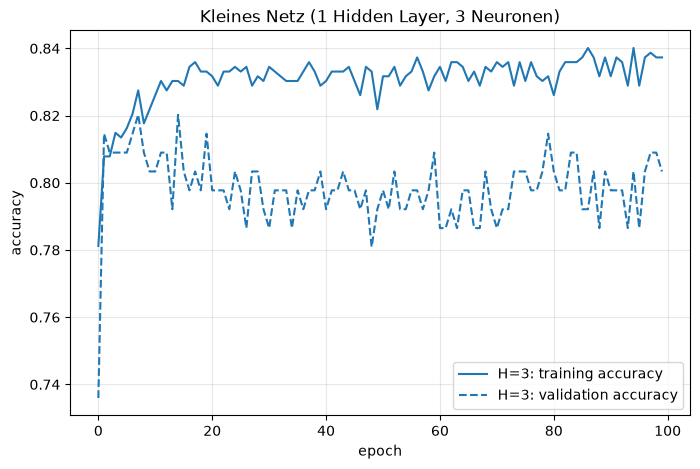

In [16]:
def plot_history(histories, title):
    """histories: dict label -> history. Trainings- und Validierungs-Accuracy pro Epoche."""
    fig, ax = plt.subplots(figsize=(8, 5))
    for label, h in histories.items():
        line, = ax.plot(h["train_acc"], label=f"{label}: training accuracy")
        ax.plot(h["val_acc"], linestyle="--", color=line.get_color(), label=f"{label}: validation accuracy")
    ax.set_xlabel("epoch")
    ax.set_ylabel("accuracy")
    ax.set_title(title)
    ax.grid(alpha=0.3)
    ax.legend()
    plt.show()


plot_history({"H=3": hist_small}, "Kleines Netz (1 Hidden Layer, 3 Neuronen)")

## 5. Komplexeres Netz – Overfitting

Epoch   1/300  train loss 0.4366 acc 0.819 | val loss 0.4596 acc 0.798
Epoch  30/300  train loss 0.3011 acc 0.857 | val loss 0.6064 acc 0.775
Epoch  60/300  train loss 0.2434 acc 0.898 | val loss 0.6554 acc 0.803
Epoch  90/300  train loss 0.2301 acc 0.906 | val loss 0.9298 acc 0.798
Epoch 120/300  train loss 0.1980 acc 0.921 | val loss 0.9774 acc 0.787
Epoch 150/300  train loss 0.1887 acc 0.924 | val loss 2.0578 acc 0.792
Epoch 180/300  train loss 0.1836 acc 0.931 | val loss 1.8781 acc 0.803
Epoch 210/300  train loss 0.1621 acc 0.941 | val loss 2.0788 acc 0.798
Epoch 240/300  train loss 0.1722 acc 0.931 | val loss 2.2622 acc 0.781
Epoch 270/300  train loss 0.1476 acc 0.937 | val loss 2.4328 acc 0.787
Epoch 300/300  train loss 0.1380 acc 0.945 | val loss 2.5431 acc 0.781


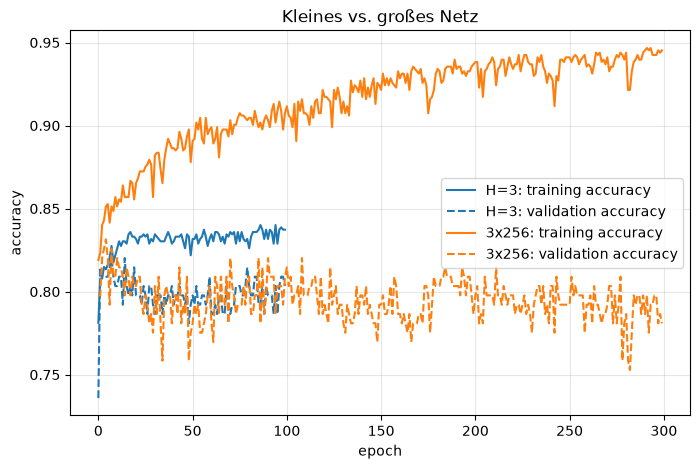

In [17]:
class DeepNet(nn.Module):
    """Mehrere große Hidden Layers, optional mit Dropout nach jeder Hidden Layer."""

    def __init__(self, D_in, hidden=(256, 256, 256), p_dropout=0.0):
        super().__init__()
        layers, prev = [], D_in
        for h in hidden:
            layers += [nn.Linear(prev, h), nn.ReLU()]
            if p_dropout > 0:
                layers.append(nn.Dropout(p_dropout))
            prev = h
        layers += [nn.Linear(prev, 1), nn.Sigmoid()]
        self.net = nn.Sequential(*layers)

    def forward(self, x):
        return self.net(x)


torch.manual_seed(42)
model_big, hist_big = run_training(DeepNet(D_in), n_epochs=300, lr=0.001)
plot_history({"H=3": hist_small, "3x256": hist_big}, "Kleines vs. großes Netz")

## 6. Dropout gegen Overfitting

Epoch   1/300  train loss 0.4847 acc 0.790 | val loss 0.5039 acc 0.753
Epoch  30/300  train loss 0.3524 acc 0.844 | val loss 0.4516 acc 0.815
Epoch  60/300  train loss 0.3208 acc 0.865 | val loss 0.4660 acc 0.809
Epoch  90/300  train loss 0.3032 acc 0.872 | val loss 0.4883 acc 0.815
Epoch 120/300  train loss 0.2858 acc 0.878 | val loss 0.5346 acc 0.809
Epoch 150/300  train loss 0.2780 acc 0.881 | val loss 0.5797 acc 0.803
Epoch 180/300  train loss 0.2707 acc 0.884 | val loss 0.5826 acc 0.815
Epoch 210/300  train loss 0.2636 acc 0.886 | val loss 0.6013 acc 0.809
Epoch 240/300  train loss 0.2532 acc 0.891 | val loss 0.6606 acc 0.798
Epoch 270/300  train loss 0.2524 acc 0.893 | val loss 0.7111 acc 0.792
Epoch 300/300  train loss 0.2465 acc 0.892 | val loss 0.6778 acc 0.815


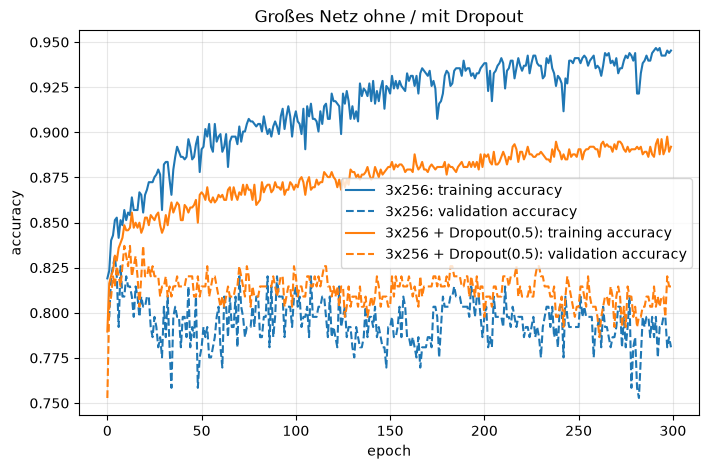

H=3                final train acc 0.837 | final val acc 0.803 | best val acc 0.820
3x256              final train acc 0.945 | final val acc 0.781 | best val acc 0.831
3x256 + Dropout    final train acc 0.892 | final val acc 0.815 | best val acc 0.837


In [ ]:
torch.manual_seed(42)
model_drop, hist_drop = run_training(DeepNet(D_in, p_dropout=0.5), n_epochs=300, lr=0.001)
plot_history({"3x256": hist_big, "3x256 + Dropout(0.5)": hist_drop}, "Großes Netz ohne / mit Dropout")

model_drop2, hist_drop2 = run_training(DeepNet(D_in, p_dropout=0.2), n_epochs=300, lr=0.001)
plot_history({"3x256": hist_big, "3x256 + Dropout(0.5)": hist_drop2}, "Großes Netz ohne / mit Dropout")

for name, h in [("H=3", hist_small), ("3x256", hist_big), ("3x256 + Dropout", hist_drop)]:
    print("{:18s} final train acc {:.3f} | final val acc {:.3f} | best val acc {:.3f}".format(
        name, h["train_acc"][-1], h["val_acc"][-1], max(h["val_acc"])))